**Eye-Tracking & Neurocognitive Intelligence | Reading Comprehension & Neurocognitive Modelling | Presented by: Reza Saadatyar (2026)**

**03 | Classical ML and Text-Based Baselines**

![Classical ML and Text-Based Baselines — scientific workflow](../../images/03_classical_ml_and_text_baselines.svg)

**Objective:** Compare gaze-only, text-only and combined classical predictors, including a training-fitted lexical TF-IDF comparator.

**Dataset:** Trial-level feature table, fixed participant assignments and local paragraph-text table from Notebook 02.

**Scope:** Fit fixed classical candidates and compare gaze, text and combined representations using Validation; save held-out scores.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("reading_comprehension_modelling")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# --------------------------- 3. Study Dependencies ---------------------------
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r",
     str(root / "reading_comprehension_modelling" / "requirements.txt")],
    check=True,
)

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import pandas as pd

# ------------------- 5. Classical Modelling and Evaluation -------------------
from reading_models import classical_predictions, CLASSICAL
from reading_evaluation import metric

# ------------------- 6. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 7. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from onestop_io import validate_splits, validate_trial_index

# ------------------- 8. Output Directory and Setup Summary -------------------
out_dir = root / "reading_comprehension_modelling" / "output"
out_dir.mkdir(parents=True, exist_ok=True)
processed = root / "data" / "processed" / "onestop"
processed.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)
print("Study outputs:", out_dir)
print("Local data directory:", processed)
print("Python:", sys.version.split()[0])


Repository up to date.
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/reading_comprehension_modelling/output
Local data directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/processed/onestop
Python: 3.13.16


**02. Load Matched Trial Features and Participant Roles**

Load the 9,718 trial-level feature rows and fixed participant assignments from Notebooks 01–02. Match the local whole-paragraph text to the trial identities for lexical modelling. Identity fields, answer metadata and information from the question or response period are excluded from the predictor allowlists.

In [3]:
# =========== 02. Load Matched Trial Features and Participant Roles ===========

# ------------------- 1. Load and Reconcile Trial Features --------------------
identity = ["trial_id","participant_id","trial_index","article_batch",
            "article_key","paragraph_key","question_key","difficulty_level"]
table = pd.read_csv(out_dir/"02_trial_features.csv",dtype={c:str for c in identity})
index = pd.read_csv(out_dir/"01_trial_index.csv",dtype=str)
index["is_correct"] = index.is_correct.astype(int)
validate_trial_index(index,table)

# --------------- 2. Load Participant Roles and Paragraph Text ----------------
splits = pd.read_csv(out_dir/"01_participant_splits.csv",dtype=str)
paragraph_text = pd.read_csv(processed/"02_paragraph_text.csv",dtype=str)
validate_splits(table,splits)
print("Classical candidates:",CLASSICAL)


Classical candidates: ['prior', 'logistic_gaze', 'logistic_text', 'logistic_fusion', 'forest_gaze', 'forest_text', 'forest_fusion', 'xgb_gaze', 'xgb_text', 'xgb_fusion', 'tfidf_text', 'tfidf_fusion']


**03. Fit Classical Models and Lexical Baselines**

Compare a Training-prevalence reference, Logistic Regression, Random Forest and XGBoost using gaze-only, text-only and combined scalar features. The two lexical comparators use unigram and bigram term frequency–inverse document frequency (TF-IDF) features with Logistic Regression and static paragraph features, with or without additional gaze features.

Imputation, scaling, vocabulary fitting and class weighting use Training only. The decision threshold is 0.5. All 12 candidates are evaluated in each protocol, producing 101,064 Validation and Test scores without outcome columns. Per candidate, Protocol A contributes 1,943 Validation and 1,944 Test trials; Protocol B contributes 1,295 Validation and 3,240 Test trials.

In [4]:
# ============== 03. Fit Classical Models and Lexical Baselines ===============

# --------------------- 1. Fit Fixed Classical Candidates ---------------------
classical, importance = classical_predictions(table,splits,paragraph_text,seed=17)

# --------------------- 2. Summarise Prediction Coverage ----------------------
print("Prediction rows:",len(classical))


Prediction rows: 101064


**04. Examine Validation Evidence**

Compare the fixed candidates using Validation labels only. Test scores are retained for the final evaluation in Notebook 05. Scalar-feature permutation importance measures the decrease in Validation Macro F1 following permutation (three repeats), not a causal effect.

TF-IDF fusion has the highest classical Validation Macro F1 in Protocol A (0.5571); TF-IDF text has the highest in Protocol B (0.5702). The prevalence references achieve Macro F1 of 0.4472 and 0.4487, with zero incorrect-response recall despite accuracy near 81%. Fusion minus matched TF-IDF text is +0.0088 in A and −0.0088 in B. Adding gaze does not consistently improve Validation performance across estimator families, although all three scalar fusion variants outperform their gaze-only counterparts in both protocols.

The permutation table contains 168 feature-level summaries. For example, the mean decrease in Macro F1 is 0.0519 for fixation count in A Logistic Regression fusion and 0.0594 for mean word length in B Logistic Regression fusion. Repeat SD describes variation across permutations, not a confidence interval. These comparisons are descriptive. Both Validation partitions share development articles with Training; Protocol B's unseen-article evaluation uses its Test partition.

,protocol,model,n_trials,accuracy,macro_f1,balanced_accuracy,auroc,incorrect_auprc,incorrect_precision,incorrect_recall,brier
7,A_unseen_people,tfidf_fusion,1943,0.630468,0.557059,0.613064,0.652545,0.294318,0.277849,0.584906,0.223391
8,A_unseen_people,tfidf_text,1943,0.615543,0.548231,0.610017,0.641563,0.291743,0.271290,0.601078,0.228761
2,A_unseen_people,forest_text,1943,0.609882,0.538313,0.593133,0.626358,0.269948,0.260223,0.566038,0.223845
9,A_unseen_people,xgb_fusion,1943,0.605764,0.516463,0.550433,0.592387,0.264384,0.232022,0.460916,0.233615
11,A_unseen_people,xgb_text,1943,0.559959,0.511845,0.592141,0.637947,0.302416,0.248441,0.644205,0.235017
3,A_unseen_people,logistic_fusion,1943,0.578487,0.510961,0.564465,0.595281,0.258763,0.236471,0.541779,0.240239
10,A_unseen_people,xgb_gaze,1943,0.579516,0.491597,0.521856,0.537014,0.213364,0.208115,0.428571,0.240681
5,A_unseen_people,logistic_text,1943,0.545033,0.491393,0.557176,0.580649,0.241002,0.227418,0.576819,0.245929
4,A_unseen_people,logistic_gaze,1943,0.555327,0.487908,0.535737,0.553226,0.226993,0.215686,0.504043,0.243120
0,A_unseen_people,forest_fusion,1943,0.795162,0.479628,0.507886,0.576555,0.237990,0.271186,0.043127,0.167609


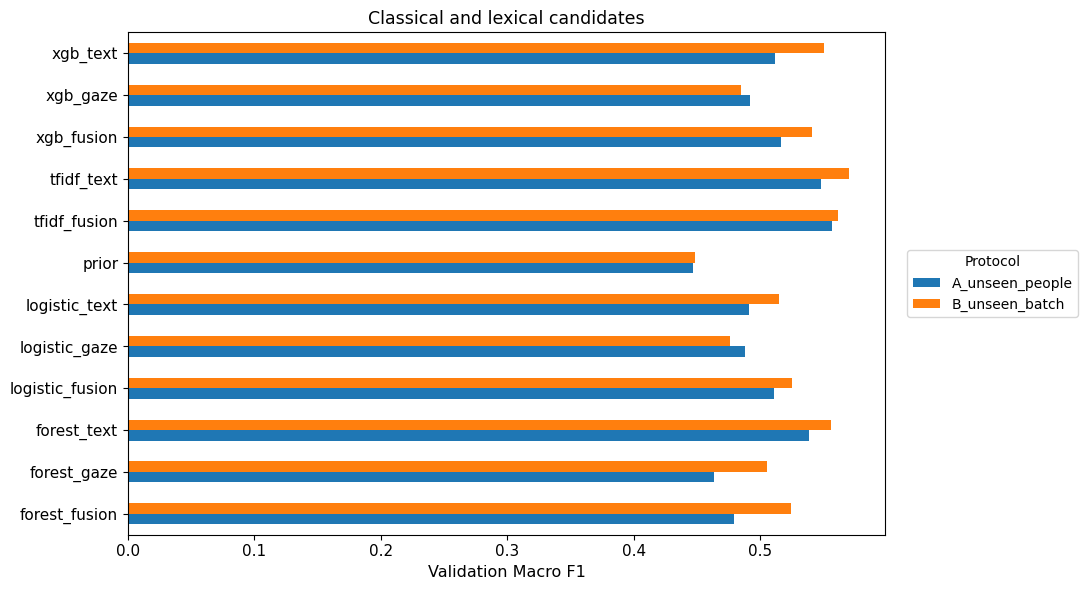

In [5]:
# ====================== 04. Examine Validation Evidence ======================

# -------------------- 1. Summarise Validation Performance --------------------
v = classical[classical.role.eq("validation")].merge(
    table[["trial_id","is_correct"]],on="trial_id",validate="many_to_one")
validation = pd.DataFrame([dict(protocol=p,model=m,**metric(g.is_correct,g.p_correct))
                           for (p,m),g in v.groupby(["protocol","model"])])
display(validation.sort_values(["protocol","macro_f1"],ascending=[True,False]))

# ----------------------- 2. Plot Validation Comparison -----------------------
fig, ax = plt.subplots(figsize=(11,6))
validation.pivot(index="model",columns="protocol",values="macro_f1").plot.barh(ax=ax)
ax.set(xlabel="Validation Macro F1",ylabel="",title="Classical and lexical candidates")
ax.legend(title="Protocol", loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.tight_layout()
save_figure(fig,out_dir/"03_validation_comparison.png")
plt.show()


**05. Save Classical Prediction Scores**

Save one score per candidate and Validation or Test trial, together with the Validation metrics, permutation-importance table and comparison figure. Notebook 05 combines `03_classical_predictions.csv` with the neural scores from Notebook 04 for Validation-based selection and held-out evaluation.

In [6]:
# =================== 05. Save Classical Prediction Scores ====================

# ---------------- 1. Save Predictions and Validation Evidence ----------------
classical.to_csv(out_dir/"03_classical_predictions.csv",index=False)
validation.to_csv(out_dir/"03_validation_metrics.csv",index=False)
importance.to_csv(out_dir/"03_validation_feature_importance.csv",index=False)

# ------------------------ 2. Package Current Outputs -------------------------
download_outputs_from_colab(out_dir,"03")


------------------------------------------------------------------------
Notebook 03
Files packaged: 4
  + 03_classical_predictions.csv
  + 03_validation_comparison.png
  + 03_validation_feature_importance.csv
  + 03_validation_metrics.csv
Download ZIP from Colab Contents: /content/reading_comprehension_modelling_Notebook_03_Outputs.zip
